# Lab 02 — Document intelligence: OCR and multilingual embeddings

**Level:** Beginner → Intermediate · **Duration:** ~75 minutes · **Covers:** H3 OCR lab (45 min) · H4 multilingual embeddings mini-lab (30 min)

Lab guide: [`../lab-02-ocr-multilingual-embeddings.md`](../lab-02-ocr-multilingual-embeddings.md) — read each part there first; this notebook holds the code.

You compare two approaches twice: traditional OCR against AI-assisted OCR, and an English-only embedding model against a multilingual one. Two functions are yours to write (marked `TODO`); the check cells tell you when they meet their contract.

In [1]:
# (notebook) Setup: run this cell first. It loads the repo-root .env and creates both SDK clients.
import json
import os
import sys
import time
from pathlib import Path

import anthropic
import openai
import pandas as pd
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))  # walks up from this folder to the repo-root .env

# labs/module-01 holds data/ and templates/; the notebook runs from notebooks/ or solutions/.
LAB_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "module-01" and (p / "data").is_dir())
DATA_DIR = LAB_DIR / "data"
SETUP_DIR = LAB_DIR.parent / "setup"

# Model IDs come from .env, never from code (labs/setup/.env.example has the defaults).
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "").strip()
OPENAI_SMALL_MODEL = os.getenv("OPENAI_SMALL_MODEL", "").strip()
ANTHROPIC_MODEL = os.getenv("ANTHROPIC_MODEL", "").strip()
ANTHROPIC_SMALL_MODEL = os.getenv("ANTHROPIC_SMALL_MODEL", "").strip()

# Each SDK reads its key from the environment; a client exists only when key and model are set.
openai_client = openai.OpenAI() if os.getenv("OPENAI_API_KEY") and OPENAI_MODEL else None
claude_client = anthropic.Anthropic() if os.getenv("ANTHROPIC_API_KEY") and ANTHROPIC_MODEL else None


def available(provider: str) -> bool:
    """True if `provider` is configured; otherwise print why the cell skips it."""
    client = {"openai": openai_client, "anthropic": claude_client}[provider]
    if client is None:
        print(f"⚠️  {provider}: not configured, skipping. Add its key and model to .env, then restart the kernel.")
    return client is not None


def active_providers() -> list[str]:
    """The configured providers, with a printed note for each one that is skipped."""
    return [p for p in ("openai", "anthropic") if available(p)]


def claude_text(message) -> str:
    """Join the text blocks of a Claude response; thinking blocks are skipped."""
    return "".join(block.text for block in message.content if block.type == "text")


def check(name: str, fn) -> None:
    """Run a check function. A returned string means 'skipped'; a TODO is reported, not raised."""
    try:
        skipped = fn()
    except NotImplementedError as exc:
        print(f"⏳ {name}: TODO not implemented yet ({exc})")
        return
    print(f"⚠️  {name}: skipped ({skipped})" if skipped else f"✅ {name}")


print(f"Lab folder : {LAB_DIR}")
print(f"OpenAI     : {'✅ ' + OPENAI_MODEL if openai_client else '❌ OPENAI_API_KEY or OPENAI_MODEL missing'}")
print(f"Claude     : {'✅ ' + ANTHROPIC_MODEL if claude_client else '❌ ANTHROPIC_API_KEY or ANTHROPIC_MODEL missing'}")
if not (openai_client or claude_client):
    print(
        "\n❌ No provider is configured. Copy labs/setup/.env.example to the repo-root .env, add your keys,\n"
        "   restart the kernel and run this cell again. Until then, cells that call a model are skipped."
    )

import re
import shutil
import subprocess

import numpy as np
import pytesseract
from PIL import Image

SAMPLES_DIR = DATA_DIR / "samples"
if not (SAMPLES_DIR / "ground_truth.json").exists():  # the images are generated, not committed
    subprocess.run([sys.executable, str(DATA_DIR / "make_samples.py")], check=True)
GROUND_TRUTH = json.loads((SAMPLES_DIR / "ground_truth.json").read_text(encoding="utf-8"))

TESSERACT_OK = shutil.which("tesseract") is not None
print(f"Tesseract  : {'✅ ' + str(pytesseract.get_tesseract_version()) if TESSERACT_OK else '❌ not installed: Tesseract cells will skip'}")

Lab folder : /Users/saravana/AgenticAI/agentic-ai-python/labs/module-01
OpenAI     : ✅ gpt-5-mini
Claude     : ✅ claude-haiku-5-5
Tesseract  : ✅ 5.5.3


## Part 1 — Generate the samples and run Tesseract (10 min)

Four synthetic documents from the running scenario: a clean invoice, a poor scan of a second invoice
(with **no PO number printed**), a clean incident record and a phone photo of another one.
`data/make_samples.py` generated them with known text, so every OCR result can be scored exactly.

In [2]:
# (notebook) What the generator wrote, and what each image looks like.
import matplotlib.pyplot as plt

pd.DataFrame(
    [{"file": name, "type": item["doc_type"], "condition": item["condition"]} for name, item in GROUND_TRUTH.items()]
)

,file,type,condition
0,INV-88341_clean.png,invoice,clean digital render
1,INV-88342_scan.png,invoice,"low-quality scan: skew, blur, low contrast, sp..."
2,INC-104233_ticket.png,ticket,clean printout
3,INC-104251_photo.png,ticket,"phone photo: rotation, perspective, uneven lig..."


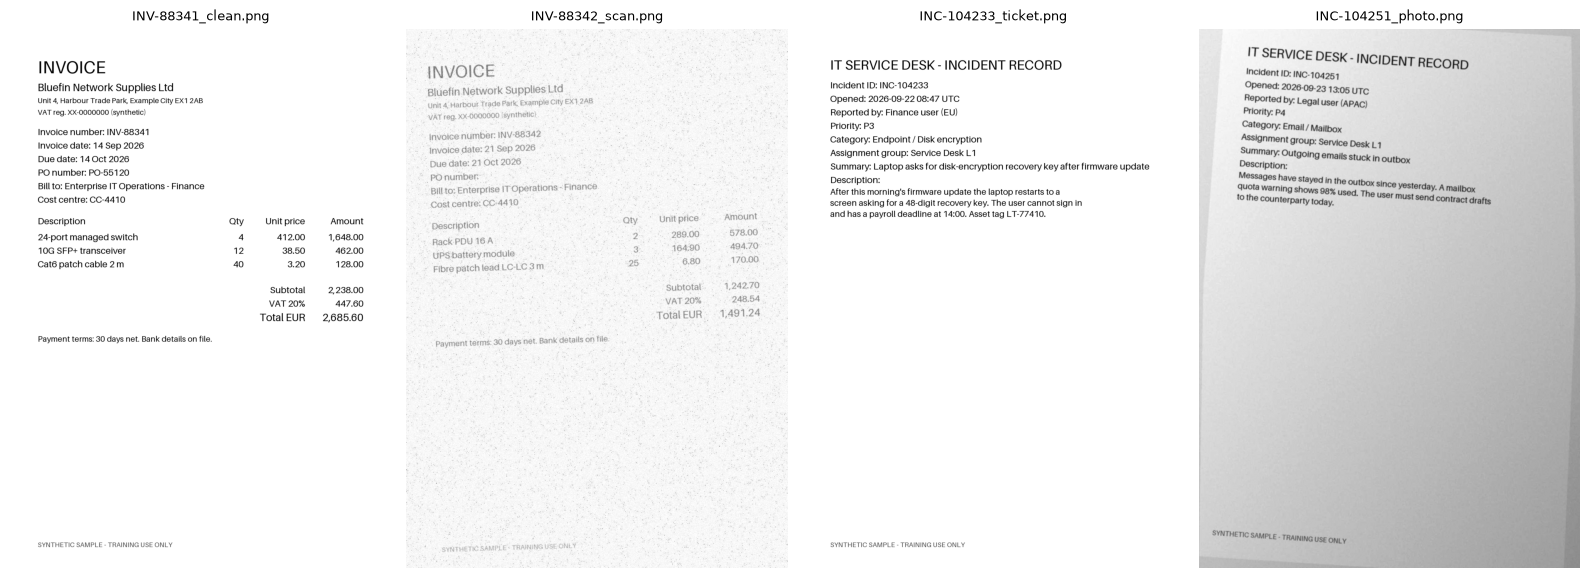

In [3]:
# (notebook) Thumbnails of the four documents.
fig, axes = plt.subplots(1, 4, figsize=(16, 6))
for ax, name in zip(axes, GROUND_TRUTH):
    ax.imshow(Image.open(SAMPLES_DIR / name), cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# (notebook) Plain Tesseract on the clean invoice, with its default settings.
CLEAN_INVOICE, SCANNED_INVOICE = "INV-88341_clean.png", "INV-88342_scan.png"

if TESSERACT_OK:
    started = time.perf_counter()
    default_text = pytesseract.image_to_string(Image.open(SAMPLES_DIR / CLEAN_INVOICE))
    print(f"({time.perf_counter() - started:.2f}s, local, no network)\n")
    print(default_text)

(0.44s, local, no network)

INVOICE

Bluefin Network Supplies Ltd
Unit 4, Harbour Trade Park, Example City EX1 2AB
VAT reg. XX-0000000 (synthetic)

Invoice number: INV-88341

Invoice date: 14 Sep 2026

Due date: 14 Oct 2026

PO number: PO-55120

Bill to: Enterprise IT Operations - Finance
Cost centre: CC-4410

Description

24-port managed switch
10G SFP+ transceiver
Cat6 patch cable 2m

Payment terms: 30 days net. Bank details on file.

SYNTHETIC SAMPLE - TRAINING USE ONLY

Qty
4
12
40

Unit price
412.00
38.50
3.20

Subtotal
VAT 20%
Total EUR

Amount
1,648.00
462.00
128.00

2,238.00
447.60
2,685.60



In [5]:
# (notebook) Word-level output: every word with its position and a confidence from 0 to 100.
if TESSERACT_OK:
    words = pytesseract.image_to_data(Image.open(SAMPLES_DIR / SCANNED_INVOICE), output_type=pytesseract.Output.DATAFRAME)
    words = words[(words.conf >= 0) & words.text.notna() & (words.text.astype(str).str.strip() != "")]
    print(f"{len(words)} words on the scan · median confidence {words.conf.median():.0f}")
    display(words.sort_values("conf")[["text", "conf", "left", "top", "block_num", "line_num"]].head(10))

110 words on the scan · median confidence 47


,text,conf,left,top,block_num,line_num
123,;,0.0,377,646,13,1
33,PAB,0.0,565,224,4,1
82,iFOperations-,0.0,313,486,8,4
131,oy,0.0,50,755,13,1
182,:,0.0,1216,877,17,2
18,Supple,0.0,323,145,3,2
64,.,0.0,53,381,8,2
179,VAT,0.0,827,874,17,2
158,gg0,0.0,837,734,14,4
174,:,0.0,994,828,17,1


In [6]:
# (notebook) Check: Tesseract read the clean invoice's ID.
def check_part1():
    if not TESSERACT_OK:
        return "Tesseract is not installed"
    assert "INV-88341" in default_text, "the invoice number should survive OCR on the clean render"
    assert len(words) > 50


check("Part 1 — Tesseract runs", check_part1)

✅ Part 1 — Tesseract runs


## Part 2 — Measure accuracy, fix the layout, clean the scan (15 min)

The **character error rate** (CER) is the edit distance between the OCR text and the true text,
divided by the length of the true text. It is 0.0 for a perfect read. You measure, fix the biggest
problem, and measure again.

In [7]:
# (notebook) CER for all four documents with Tesseract's defaults.
from rapidfuzz.distance import Levenshtein


def normalise_ws(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def cer(predicted: str, reference: str) -> float:
    """Character error rate after collapsing whitespace."""
    reference = normalise_ws(reference)
    return Levenshtein.distance(normalise_ws(predicted), reference) / max(len(reference), 1)


def ocr(image: Image.Image, psm: int | None = None) -> str:
    """Run Tesseract; psm is the page segmentation mode (None = Tesseract's default, 3)."""
    return pytesseract.image_to_string(image, config=f"--psm {psm}" if psm else "")


cer_rows = []
if TESSERACT_OK:
    for name, truth in GROUND_TRUTH.items():
        cer_rows.append({"document": name, "default (psm 3)": cer(ocr(Image.open(SAMPLES_DIR / name)), truth["text"])})
pd.DataFrame(cer_rows).round(3)

,document,default (psm 3)
0,INV-88341_clean.png,0.403
1,INV-88342_scan.png,0.499
2,INC-104233_ticket.png,0.002
3,INC-104251_photo.png,0.191


The **clean** invoice scores badly, yet its characters looked right in Part 1. Compare the reading
order: page segmentation mode 3 finds the table columns and emits them as separate blocks, so the
text is correct but out of order. Mode 4 ("a single column of text of variable sizes") keeps each
table row on one line.

In [8]:
# (notebook) Same image, two page segmentation modes: look at where the amounts end up.
if TESSERACT_OK:
    clean = Image.open(SAMPLES_DIR / CLEAN_INVOICE)
    for psm in (3, 4):
        lines = [line for line in ocr(clean, psm).splitlines() if line.strip()]
        print(f"--- psm {psm}: lines 11-17\n" + "\n".join(lines[10:17]))

--- psm 3: lines 11-17
Description
24-port managed switch
10G SFP+ transceiver
Cat6 patch cable 2m
Payment terms: 30 days net. Bank details on file.
SYNTHETIC SAMPLE - TRAINING USE ONLY
Qty
--- psm 4: lines 11-17
Description Qty Unit price Amount
24-port managed switch 4 412.00 1,648.00
10G SFP+ transceiver 12 38.50 462.00
Cat6 patch cable 2m 40 3.20 128.00
Subtotal 2,238.00
VAT 20% 447.60
TotalEUR 2,685.60


In [9]:
# (notebook) Preprocessing for the poor scan: grey, stretch contrast, despeckle, deskew, binarise.
from PIL import ImageFilter, ImageOps


def estimate_skew(image: Image.Image, limit: float = 5.0, step: float = 0.25) -> float:
    """Angle (degrees) that makes text rows most horizontal, by maximising the row-profile variance."""
    small = ImageOps.invert(image.convert("L")).resize((image.width // 3, image.height // 3))
    best_angle, best_score = 0.0, -1.0
    for angle in np.arange(-limit, limit + step, step):
        rows = np.asarray(small.rotate(float(angle), resample=Image.Resampling.BILINEAR), dtype=np.float32).sum(axis=1)
        if (score := float(np.var(rows))) > best_score:
            best_angle, best_score = float(angle), score
    return best_angle


def otsu_threshold(pixels: np.ndarray) -> int:
    """The grey level that best separates ink from paper (Otsu's method)."""
    hist = np.bincount(pixels.ravel(), minlength=256).astype(np.float64)
    levels = np.arange(256)
    weight_bg = np.cumsum(hist)
    weight_fg = pixels.size - weight_bg
    mean_bg = np.cumsum(hist * levels) / np.maximum(weight_bg, 1)
    mean_fg = (np.sum(hist * levels) - np.cumsum(hist * levels)) / np.maximum(weight_fg, 1)
    return int(np.argmax(weight_bg * weight_fg * (mean_bg - mean_fg) ** 2))


def preprocess(image: Image.Image) -> tuple[Image.Image, float]:
    """Return (clean black-and-white image, skew angle corrected)."""
    grey = ImageOps.autocontrast(ImageOps.grayscale(image), cutoff=1).filter(ImageFilter.MedianFilter(3))
    angle = estimate_skew(grey)
    grey = grey.rotate(angle, resample=Image.Resampling.BICUBIC, fillcolor=255)
    pixels = np.asarray(grey)
    return Image.fromarray(((pixels > otsu_threshold(pixels)) * 255).astype(np.uint8)), angle


if TESSERACT_OK:
    for row in cer_rows:
        image = Image.open(SAMPLES_DIR / row["document"])
        cleaned, angle = preprocess(image)
        row["psm 4"] = cer(ocr(image, 4), GROUND_TRUTH[row["document"]]["text"])
        row["preprocessed + psm 4"] = cer(ocr(cleaned, 4), GROUND_TRUTH[row["document"]]["text"])
        row["skew corrected (°)"] = angle
pd.DataFrame(cer_rows).round(3)

,document,default (psm 3),psm 4,preprocessed + psm 4,skew corrected (°)
0,INV-88341_clean.png,0.403,0.004,0.011,0.00
1,INV-88342_scan.png,0.499,0.492,0.029,-1.75
2,INC-104233_ticket.png,0.002,0.000,0.008,0.00
3,INC-104251_photo.png,0.191,0.209,0.129,3.50


### From text to fields

CER tells you how well the page was read. Finance needs **fields**. The contract for your function:

- input: OCR text of one invoice;
- output: an `InvoiceFields` object; any field you cannot find is `None`, never a guess;
- `invoice_date` as ISO `YYYY-MM-DD`, `total` as digits with a decimal point and no separators (`2685.60`).

In [12]:
# (notebook) The target schema: shared by the regex extractor (Part 2) and the vision models (Part 3).
from datetime import datetime
from decimal import Decimal, InvalidOperation

from pydantic import BaseModel, Field


class InvoiceFields(BaseModel):
    invoice_id: str | None = Field(description="Invoice number exactly as printed, e.g. INV-12345")
    invoice_date: str | None = Field(description="Invoice date as ISO 8601 YYYY-MM-DD")
    po_number: str | None = Field(description="Purchase-order number exactly as printed, or null if the document shows none")
    vendor_name: str | None = Field(description="The supplier's name as printed")
    currency: str | None = Field(description="ISO 4217 currency code of the total, e.g. EUR")
    total: str | None = Field(description="Grand total as digits with a decimal point and no separators, e.g. 2685.60")


def field_matches(field: str, predicted: str | None, expected: str | None) -> bool:
    """Compare one field; a blank prediction counts as None, an invented value never does."""
    predicted = (predicted or "").strip() or None
    if expected is None or predicted is None:
        return predicted is expected
    if field == "total":
        try:
            return Decimal(predicted.replace(",", "")) == Decimal(expected)
        except InvalidOperation:
            return False
    return predicted.casefold() == expected.casefold()


def field_report(predicted: InvoiceFields, expected: dict) -> dict[str, bool]:
    return {name: field_matches(name, getattr(predicted, name), value) for name, value in expected.items()}

In [15]:
# (notebook) Rule-based field extraction from OCR text.
def extract_invoice_fields(text: str) -> InvoiceFields:
    """Pull the six invoice fields out of OCR text with regular expressions; None when absent.

    Hints (the printed labels are in the images):
      - invoice_id:   "INV-" followed by five digits
      - invoice_date: after "Invoice date:", e.g. "14 Sep 2026" → datetime.strptime(..., "%d %b %Y")
      - po_number:    after "PO number:" on the SAME line; match [ \t]* not \s* so a blank field stays None
      - vendor_name:  the line that ends in "Ltd"
      - currency, total: "Total EUR 2,685.60" → "EUR", "2685.60". Look at your OCR text first:
        Tesseract may drop the space ("TotalEUR"), so match \s* rather than \s+
    """
    # TODO: implement with re.search(...) and return InvoiceFields(...)
    raise NotImplementedError("extract_invoice_fields")

In [16]:
# (notebook) Run your extractor on the preprocessed psm-4 text of both invoices.
tesseract_fields = {}
if TESSERACT_OK:
    try:
        for name in (CLEAN_INVOICE, SCANNED_INVOICE):
            cleaned, _ = preprocess(Image.open(SAMPLES_DIR / name))
            tesseract_fields[name] = extract_invoice_fields(ocr(cleaned, 4))
    except NotImplementedError:
        print("⏳ extract_invoice_fields is still a TODO")
pd.DataFrame(
    {name: field_report(fields, GROUND_TRUTH[name]["fields"]) for name, fields in tesseract_fields.items()}
)

⏳ extract_invoice_fields is still a TODO


""


In [17]:
# (notebook) Check: CER table complete, preprocessing helps the scan, extractor meets its contract.
def check_part2():
    if not TESSERACT_OK:
        return "Tesseract is not installed"
    assert len(cer_rows) == len(GROUND_TRUTH) and all("preprocessed + psm 4" in row for row in cer_rows)
    scan = next(row for row in cer_rows if row["document"] == SCANNED_INVOICE)
    assert scan["preprocessed + psm 4"] < scan["default (psm 3)"], "preprocessing should lower the scan's CER"
    sample = "Invoice number: INV-12345\nInvoice date: 02 Jan 2026\nPO number:\nAcme Parts Ltd\nTotal EUR 1,234.50"
    fields = extract_invoice_fields(sample)
    assert isinstance(fields, InvoiceFields)
    assert (fields.invoice_id, fields.invoice_date, fields.po_number) == ("INV-12345", "2026-01-02", None)
    assert (fields.currency, fields.total) == ("EUR", "1234.50")
    assert field_report(tesseract_fields[CLEAN_INVOICE], GROUND_TRUTH[CLEAN_INVOICE]["fields"])["invoice_id"]


check("Part 2 — CER and field extraction", check_part2)

⏳ Part 2 — CER and field extraction: TODO not implemented yet (extract_invoice_fields)


## Part 3 — AI-assisted OCR with OpenAI and Claude vision (15 min)

A multimodal model reads the image **and** fills the schema in one step. You send the same image
and the same `InvoiceFields` schema to both providers, then compare accuracy, latency and tokens with
Tesseract + regex.

In [18]:
# (notebook) One extraction function per provider: same image, same schema, structured output.
import base64

EXTRACTION_PROMPT = (
    "Extract the invoice fields from this scanned invoice. Copy values exactly as printed. "
    "Use null for any field that is not printed; never guess."
)


def image_b64(path: Path) -> str:
    return base64.standard_b64encode(path.read_bytes()).decode("ascii")


def extract_openai(path: Path, schema: type[BaseModel] = InvoiceFields) -> tuple[BaseModel, float, int]:
    started = time.perf_counter()
    response = openai_client.responses.parse(
        model=OPENAI_MODEL,
        input=[
            {
                "role": "user",
                "content": [
                    {"type": "input_text", "text": EXTRACTION_PROMPT},
                    {"type": "input_image", "image_url": f"data:image/png;base64,{image_b64(path)}", "detail": "high"},
                ],
            }
        ],
        text_format=schema,
        reasoning={"effort": "low"},
        max_output_tokens=4_000,
    )
    return response.output_parsed, time.perf_counter() - started, response.usage.total_tokens


def extract_claude(path: Path, schema: type[BaseModel] = InvoiceFields) -> tuple[BaseModel, float, int]:
    started = time.perf_counter()
    message = claude_client.messages.parse(
        model=ANTHROPIC_MODEL,
        max_tokens=4_000,
        output_config={"effort": "low"},
        output_format=schema,
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "image", "source": {"type": "base64", "media_type": "image/png", "data": image_b64(path)}},
                    {"type": "text", "text": EXTRACTION_PROMPT},
                ],
            }
        ],
    )
    usage = message.usage
    return message.parsed_output, time.perf_counter() - started, usage.input_tokens + usage.output_tokens


EXTRACT = {"openai": extract_openai, "anthropic": extract_claude}
vision_results = {}
for provider in active_providers():
    for name in (CLEAN_INVOICE, SCANNED_INVOICE):
        fields, seconds, tokens = EXTRACT[provider](SAMPLES_DIR / name)
        vision_results[(provider, name)] = fields
        print(f"{provider:>9} · {name:<20} {seconds:5.1f}s · {tokens:>5} tokens · {fields.model_dump()}")

   openai · INV-88341_clean.png    4.3s ·  3153 tokens · {'invoice_id': 'INV-88341', 'invoice_date': '14 Sep 2026', 'po_number': 'PO-55120', 'vendor_name': 'Bluefin Network Supplies Ltd', 'currency': 'EUR', 'total': '2,685.60'}
   openai · INV-88342_scan.png     6.4s ·  3132 tokens · {'invoice_id': 'INV-88342', 'invoice_date': '2026-09-21', 'po_number': None, 'vendor_name': 'Bluefin Network Supplies Ltd', 'currency': 'EUR', 'total': '1491.24'}
anthropic · INV-88341_clean.png    3.7s ·  3744 tokens · {'invoice_id': 'INV-88341', 'invoice_date': '2026-09-14', 'po_number': 'PO-55120', 'vendor_name': 'Bluefin Network Supplies Ltd', 'currency': 'EUR', 'total': '2685.60'}
anthropic · INV-88342_scan.png     2.8s ·  3740 tokens · {'invoice_id': 'INV-88342', 'invoice_date': '2026-09-21', 'po_number': None, 'vendor_name': 'Bluefin Network Supplies Ltd', 'currency': 'EUR', 'total': '1491.24'}


In [19]:
# (notebook) Field accuracy: Tesseract + regex versus the two vision models.
comparison = {}
for name in (CLEAN_INVOICE, SCANNED_INVOICE):
    expected = GROUND_TRUTH[name]["fields"]
    if name in tesseract_fields:
        comparison[("tesseract+regex", name)] = field_report(tesseract_fields[name], expected)
    for provider in ("openai", "anthropic"):
        if (provider, name) in vision_results:
            comparison[(provider, name)] = field_report(vision_results[(provider, name)], expected)
accuracy = pd.DataFrame(comparison).astype(int)  # 1 = field correct
if not accuracy.empty:
    accuracy.loc["fields correct"] = accuracy.sum()
accuracy

,openai,anthropic,openai,anthropic
,INV-88341_clean.png,INV-88341_clean.png,INV-88342_scan.png,INV-88342_scan.png
invoice_id,1,1,1,1
invoice_date,0,1,1,1
po_number,1,1,1,1
vendor_name,1,1,1,1
currency,1,1,1,1
total,1,1,1,1
fields correct,5,6,6,6


### Deliberate failure: a schema that forbids "not there"

`INV-88342` has an empty PO number field. The prompt says "use null", but what if the **schema**
someone wrote makes `po_number` a required string? The model must return *some* string.

In [ ]:
# (notebook) The same extraction with po_number: str (no null allowed).
class InvoiceFieldsNoNull(InvoiceFields):
    po_number: str = Field(description="Purchase-order number")


forced = []
for provider in active_providers():
    nullable, _, _ = EXTRACT[provider](SAMPLES_DIR / SCANNED_INVOICE)
    strict, _, _ = EXTRACT[provider](SAMPLES_DIR / SCANNED_INVOICE, schema=InvoiceFieldsNoNull)
    forced.append(
        {
            "provider": provider,
            "po_number (nullable schema)": nullable.po_number,
            "po_number (no-null schema)": strict.po_number,
            "no-null value correct?": field_matches("po_number", strict.po_number, None),
        }
    )
pd.DataFrame(forced)

In [ ]:
# (notebook) Check: every vision result parsed into the schema.
def check_part3():
    if not vision_results:
        return "no provider configured"
    assert all(isinstance(fields, InvoiceFields) for fields in vision_results.values())
    assert all(isinstance(row["no-null value correct?"], bool) for row in forced)
    assert all(isinstance(row["po_number (no-null schema)"], str) for row in forced), "the no-null schema must return a string"


check("Part 3 — AI-assisted OCR", check_part3)

## Part 4 — Cloud OCR comparison: instructor demo (5 min)

Your instructor runs **Azure AI Vision Read** on the same four images
(`labs/module-01/instructor/cloud_ocr_demo.py`). You need no Azure credentials. If the instructor
shares the result files, copy them into `data/cloud_ocr/` and run the next cell; otherwise watch the
screen and fill in the observation table.

> **Currency note.** Microsoft retires the Image Analysis API, Read included, on 25 September 2028
> and recommends **Azure Document Intelligence** (prebuilt Read model) for OCR. AWS Textract is the
> AWS counterpart; the outline covers it as an overview, with no lab.

In [ ]:
# (notebook) If the instructor's cloud OCR results are present, add them to the CER table.
cloud_dir = DATA_DIR / "cloud_ocr"
cloud_files = sorted(cloud_dir.glob("*.azure.json")) if cloud_dir.is_dir() else []
if not cloud_files:
    print("ℹ️  No cloud OCR results in data/cloud_ocr/: watch the instructor's demo and fill in the table below.")
else:
    for path in cloud_files:
        name = path.name.removesuffix(".azure.json")
        result = json.loads(path.read_text(encoding="utf-8"))
        for row in cer_rows:
            if row["document"] == name:
                row["Azure AI Vision Read"] = cer(result["text"], GROUND_TRUTH[name]["text"])
    display(pd.DataFrame(cer_rows).round(3))

📝 **Record (Parts 1–4).**

| Criterion | Tesseract (local) | AI-assisted (OpenAI / Claude) | Cloud OCR (Azure AI Vision) |
| --------- | ----------------- | ----------------------------- | --------------------------- |
| CER or field accuracy on the scan | | | |
| Handles table layout | | | |
| Gives per-word confidence | | | |
| Latency per page | | | |
| Cost model | free (your CPU) | per token | per transaction |
| Data leaves your network? | no | yes | yes (choose the region) |
| Can invent a value that is not on the page? | no | | |

## Part 5 — Multilingual embeddings and semantic similarity (15 min)

An embedding model maps text to a vector so that similar meanings land close together; cosine
similarity measures "close". You compare an **English-only** model with a **multilingual** one on the
same sentence written in six languages.

In [ ]:
# (notebook) Load both Sentence Transformers models (cached by labs/setup/prefetch_models.py).
from sentence_transformers import SentenceTransformer

EMBEDDING_MODELS = {
    "english-only": "sentence-transformers/all-MiniLM-L6-v2",
    "multilingual": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
}
encoders = {}
for label, model_id in EMBEDDING_MODELS.items():
    try:
        encoders[label] = SentenceTransformer(model_id)
    except OSError as exc:
        print(f"⚠️  {model_id} unavailable ({exc.__class__.__name__}): run labs/setup/prefetch_models.py")
    else:
        dims = encoders[label].get_embedding_dimension()
        print(f"{label:>12}: {model_id} · {dims} dimensions")

In [ ]:
# (notebook) One sentence, six languages: similarity of each version to the English one.
SAME_SENTENCE = {
    "en": "The VPN client rejects my new password",
    "de": "Der VPN-Client lehnt mein neues Passwort ab",
    "fr": "Le client VPN refuse mon nouveau mot de passe",
    "es": "El cliente VPN rechaza mi nueva contraseña",
    "hi": "VPN क्लाइंट मेरा नया पासवर्ड अस्वीकार कर रहा है",
    "ja": "VPNクライアントが新しいパスワードを拒否します",
}
cross_lingual = {}
for label, encoder in encoders.items():
    vectors = encoder.encode(list(SAME_SENTENCE.values()), normalize_embeddings=True)
    cross_lingual[label] = dict(zip(SAME_SENTENCE, (vectors @ vectors[0]).round(2)))
pd.DataFrame(cross_lingual).T

In [ ]:
# (notebook) The full 6 × 6 similarity matrix for the multilingual model.
if "multilingual" in encoders:
    vectors = encoders["multilingual"].encode(list(SAME_SENTENCE.values()), normalize_embeddings=True)
    matrix = vectors @ vectors.T
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(6), SAME_SENTENCE)
    ax.set_yticks(range(6), SAME_SENTENCE)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white")
    fig.colorbar(image)
    ax.set_title("multilingual MiniLM: cosine similarity")
    plt.show()

In [ ]:
# (notebook) Meaning versus shared words, and two traps: negation and identifiers (guide §7.5).
PAIRS = [
    ("My laptop won't connect to the VPN", "Remote-access tunnel fails to establish"),  # same meaning, no shared words
    ("My laptop won't connect to the VPN", "My laptop won't connect to the printer"),  # shared words, different problem
    ("My laptop won't connect to the VPN", "The canteen is closed today"),  # unrelated
    ("The VPN works after the password change", "The VPN does not work after the password change"),  # negation
    ("Escalate INC-104233 to Network Ops", "Escalate INC-104234 to Network Ops"),  # different incident
]


def word_overlap(a: str, b: str) -> float:
    """Jaccard overlap of lower-cased words: a lexical baseline."""
    wa, wb = set(re.findall(r"\w+", a.lower())), set(re.findall(r"\w+", b.lower()))
    return len(wa & wb) / len(wa | wb)


rows = []
for a, b in PAIRS:
    row = {"sentence A": a, "sentence B": b, "word overlap": round(word_overlap(a, b), 2)}
    for label, encoder in encoders.items():
        va, vb = encoder.encode([a, b], normalize_embeddings=True)
        row[f"cosine ({label})"] = round(float(va @ vb), 2)
    rows.append(row)
pd.DataFrame(rows)

In [ ]:
# (notebook) Check: the similarity results have the right shape.
def check_part5():
    if not encoders:
        return "no embedding model available"
    for label, scores in cross_lingual.items():
        assert abs(scores["en"] - 1.0) < 1e-3, "a sentence is identical to itself"
    if {"english-only", "multilingual"} <= set(cross_lingual):
        assert cross_lingual["multilingual"]["ja"] > cross_lingual["english-only"]["ja"]


check("Part 5 — similarity", check_part5)

## Part 6 — Match multilingual tickets to KB articles (15 min)

28 synthetic tickets in six languages, each labelled with the knowledge-base article that resolves
it, and seven English KB articles. Your matcher embeds both sides and picks the closest article.
The contract:

- `match_tickets(encoder, tickets, kb)` returns one row per ticket with the columns
  `ticket_id, language, gold_kb, predicted_kb, score, correct`;
- `score` is the cosine similarity of the best article; `correct` is `predicted_kb == gold_kb`.

In [ ]:
# (notebook) The data.
tickets = pd.read_csv(DATA_DIR / "multilingual_tickets.csv")
kb = pd.read_csv(DATA_DIR / "kb_articles.csv")
print(tickets.language.value_counts().to_dict())
kb[["kb_id", "title", "owner_team"]]

In [ ]:
# (notebook) Embed tickets and KB articles, then pick the most similar article for each ticket.
MATCH_COLUMNS = ["ticket_id", "language", "gold_kb", "predicted_kb", "score", "correct"]


def match_tickets(encoder: SentenceTransformer, tickets: pd.DataFrame, kb: pd.DataFrame) -> pd.DataFrame:
    """Return one row per ticket with its best-matching KB article (see the contract above).

    Steps:
      1. Embed each KB article as "title. summary" with normalize_embeddings=True.
      2. Embed each ticket's text the same way.
      3. similarity = ticket_vectors @ kb_vectors.T  (cosine, because the vectors are normalised)
      4. Best article per ticket = argmax over axis 1; score = the max similarity.
    """
    # TODO: implement the four steps and return a DataFrame with MATCH_COLUMNS
    raise NotImplementedError("match_tickets")

In [ ]:
# (notebook) Accuracy per language for both models.
matches = {}
try:
    for label, encoder in encoders.items():
        matches[label] = match_tickets(encoder, tickets, kb)
except NotImplementedError:
    print("⏳ match_tickets is still a TODO")

if matches:
    per_language = pd.DataFrame({label: m.groupby("language").correct.mean() for label, m in matches.items()})
    per_language.loc["ALL"] = [m.correct.mean() for m in matches.values()]
    display(per_language.round(2))
    print({label: f"median best score {m.score.median():.2f}" for label, m in matches.items()})

In [ ]:
# (notebook) Production habit: a low best score means "no confident match" → route to a human.
ESCALATE_BELOW = 0.35
for label, m in matches.items():
    unsure = m[m.score < ESCALATE_BELOW]
    print(f"{label:>12}: {len(unsure):>2} of {len(m)} tickets would go to a human (score < {ESCALATE_BELOW})")

In [ ]:
# (notebook) End to end: ticket IMAGE → OCR → embedding → KB article.
def ticket_text(name: str) -> str:
    """OCR text of a ticket image; falls back to the ground-truth text without Tesseract."""
    if not TESSERACT_OK:
        return GROUND_TRUTH[name]["text"]
    cleaned, _ = preprocess(Image.open(SAMPLES_DIR / name))
    return ocr(cleaned, 4)


pipeline = []
if "multilingual" in encoders and matches:
    encoder = encoders["multilingual"]
    kb_vectors = encoder.encode((kb.title + ". " + kb.summary).tolist(), normalize_embeddings=True)
    for name in ("INC-104233_ticket.png", "INC-104251_photo.png"):
        vector = encoder.encode([ticket_text(name)], normalize_embeddings=True)[0]
        scores = kb_vectors @ vector
        best = int(scores.argmax())
        pipeline.append(
            {
                "image": name,
                "predicted": kb.kb_id[best],
                "title": kb.title[best],
                "score": round(float(scores[best]), 3),
                "expected": GROUND_TRUTH[name]["fields"]["kb_hint"],
            }
        )
pd.DataFrame(pipeline)

In [ ]:
# (notebook) Optional comparison: OpenAI's hosted embedding model on the same task.
# Claude has no embedding endpoint of its own; Anthropic points to Voyage AI for embeddings.
EMBEDDING_MODEL = os.getenv("OPENAI_EMBEDDING_MODEL", "").strip()
if available("openai") and EMBEDDING_MODEL and matches:
    def embed_openai(texts: list[str]) -> np.ndarray:
        data = openai_client.embeddings.create(model=EMBEDDING_MODEL, input=texts).data
        vectors = np.array([item.embedding for item in data])
        return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

    similarity = embed_openai(tickets.text.tolist()) @ embed_openai((kb.title + ". " + kb.summary).tolist()).T
    hosted_correct = kb.kb_id.to_numpy()[similarity.argmax(axis=1)] == tickets.gold_kb.to_numpy()
    print(f"{EMBEDDING_MODEL}: top-1 accuracy {hosted_correct.mean():.2f} on {len(tickets)} tickets")
elif not EMBEDDING_MODEL:
    print("ℹ️  OPENAI_EMBEDDING_MODEL is not set: skipping the hosted comparison.")

In [ ]:
# (notebook) Check: the matcher meets its contract and the multilingual model wins where it should.
def check_part6():
    if not encoders:
        return "no embedding model available"
    for label, m in matches.items():
        assert list(m.columns) == MATCH_COLUMNS, f"{label}: columns must be {MATCH_COLUMNS}"
        assert len(m) == len(tickets) and m.score.between(-1, 1).all()
        assert (m.correct == (m.predicted_kb == m.gold_kb)).all()
    if not matches:
        raise NotImplementedError("match_tickets")
    if {"english-only", "multilingual"} <= set(matches):
        assert matches["multilingual"].correct.mean() >= matches["english-only"].correct.mean()
        non_latin = matches["multilingual"][matches["multilingual"].language.isin(["hi", "ja"])]
        assert non_latin.correct.mean() >= 0.75, "the multilingual model should match Hindi and Japanese tickets"


check("Part 6 — multilingual matching", check_part6)

---

**Done.** Answer the checkpoint questions in the lab guide, then go on to
[Lab 03 — Mapping use cases and selecting models](../lab-03-use-cases-model-selection.md).